<a href="https://colab.research.google.com/github/bautylazza/TP2-CDD/blob/main/TP_2_CD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1)Análisis exploratorio de Datos

###Carga de Datos

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import zscore
import seaborn as sns
import string
import nltk
from nltk.corpus import stopwords
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from imblearn.over_sampling import SMOTE
from wordcloud import WordCloud

nltk.download('stopwords')
df = pd.read_csv('intent.csv')
df = df.rename(columns={'text': 'texto', 'category': 'categoria'})

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


### Análisis de categorías

In [ ]:
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

print("--- Información general del DataFrame ---")
df.info()

print("\n--- Conteo de valores nulos por columna ---")
print(df.isnull().sum())

print(f"\nCantidad de registros duplicados: {df.duplicated().sum()}")

print(f"\nCantidad de categorías únicas: {df['categoria'].nunique()}")
print("Tamaño del DataFrame: ", df.size)

Dimensiones del dataset: 13083 filas y 2 columnas.

--- Información general del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13083 entries, 0 to 13082
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   texto      13083 non-null  object
 1   categoria  13083 non-null  object
dtypes: object(2)
memory usage: 204.6+ KB

--- Conteo de valores nulos por columna ---
texto        0
categoria    0
dtype: int64

Cantidad de registros duplicados: 0

Cantidad de categorías únicas: 77
Tamaño del DataFrame:  26166


In [ ]:
# Visualizar los primeros registros del dataframe
print("Primeros registros del DataFrame:")
df.head()

Primeros registros del DataFrame:


,texto,categoria
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [ ]:
# Estadísticas descriptivas de las categorías
print("--- Estadísticas de la columna 'category' ---")
display(df['categoria'].describe())

--- Estadísticas de la columna 'category' ---


,categoria
count,13083
unique,77
top,card_payment_fee_charged
freq,227


### Distribución de categorías



In [ ]:
# Ver las categorías más frecuentes y las menos frecuentes
print("\n--- Top 10 Categorías más frecuentes ---")
print(df['categoria'].value_counts().head(10))


--- Top 10 Categorías más frecuentes ---
categoria
card_payment_fee_charged                            227
direct_debit_payment_not_recognised                 222
balance_not_updated_after_cheque_or_cash_deposit    221
wrong_amount_of_cash_received                       220
cash_withdrawal_charge                              217
transaction_charged_twice                           215
declined_cash_withdrawal                            213
transfer_fee_charged                                212
balance_not_updated_after_bank_transfer             211
transfer_not_received_by_recipient                  211
Name: count, dtype: int64


In [ ]:
print("\n--- Top 10 Categorías menos frecuentes ---")
print(df['categoria'].value_counts().tail(10))


--- Top 10 Categorías menos frecuentes ---
categoria
get_disposable_virtual_card    137
top_up_limits                  137
receiving_money                135
atm_support                    127
compromised_card               126
lost_or_stolen_card            122
card_swallowed                 101
card_acceptance                 99
virtual_card_not_working        81
contactless_not_working         75
Name: count, dtype: int64


/tmp/ipykernel_7809/3548024788.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='categoria', data=df, order=df['categoria'].value_counts().index, palette='viridis')


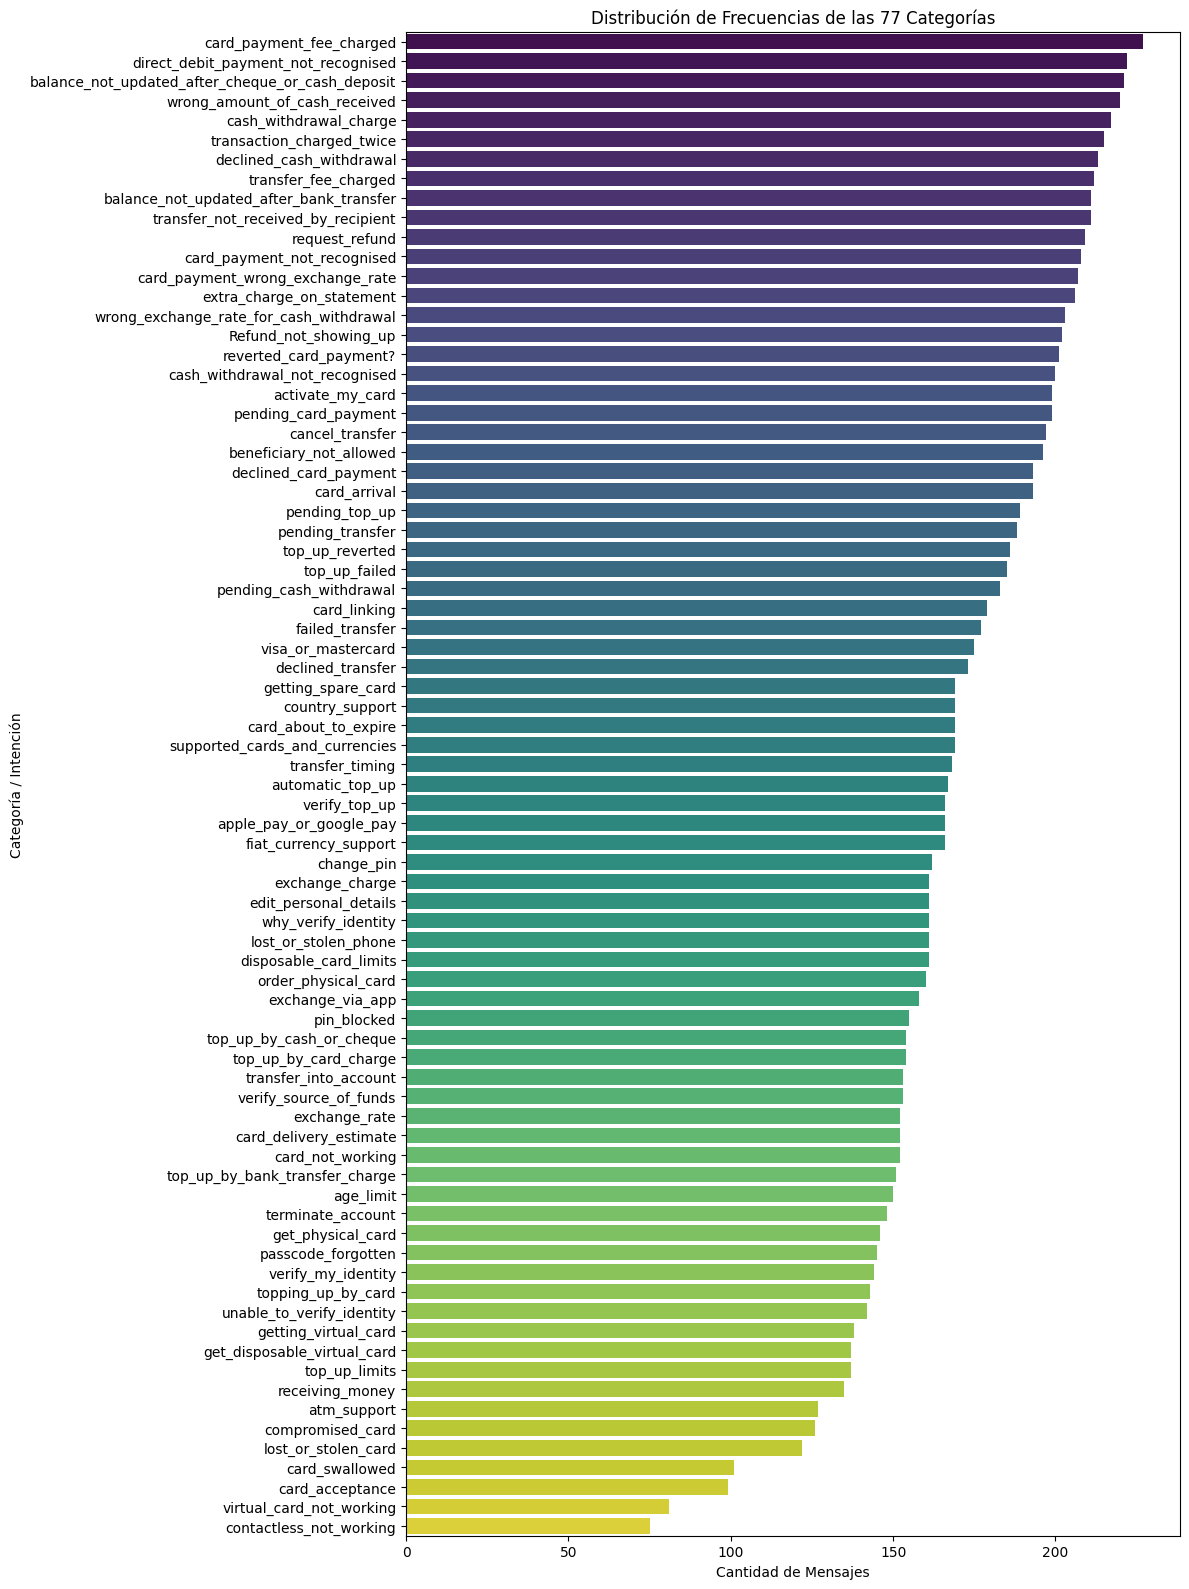

In [ ]:
# Gráfico de distribución de clases
plt.figure(figsize=(12, 16))
sns.countplot(y='categoria', data=df, order=df['categoria'].value_counts().index, palette='viridis')
plt.title('Distribución de Frecuencias de las 77 Categorías')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Categoría / Intención')
plt.tight_layout()
plt.show()

### Longitud de los mensajes

--- Estadísticas de longitud de los mensajes (en caracteres) ---


,conteo_caracteres
count,13083.000000
mean,58.239853
std,39.555232
min,13.000000
25%,36.000000
50%,46.000000
75%,63.000000
max,433.000000



--- Estadísticas de cantidad de palabras por mensaje ---


,conteo_palabras
count,13083.000000
mean,11.714744
std,7.636859
min,2.000000
25%,7.000000
50%,10.000000
75%,13.000000
max,79.000000


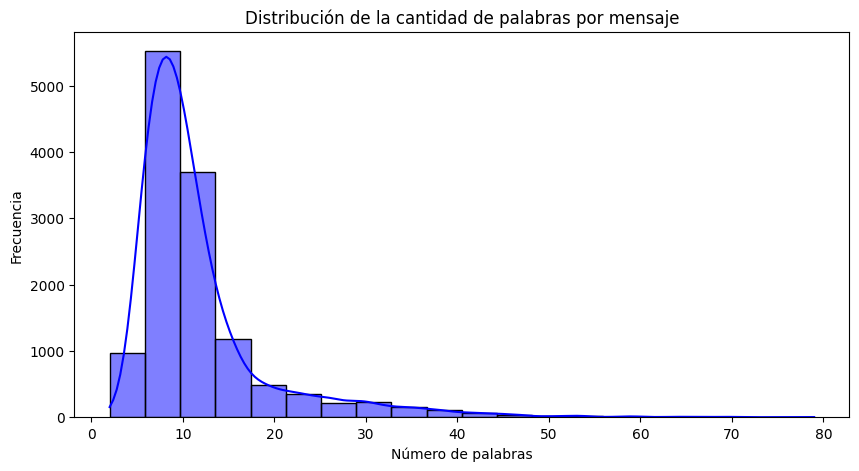

In [ ]:
# Creamos variables auxiliares para el análisis estadístico del texto
df['conteo_caracteres'] = df['texto'].astype(str).apply(len)
df['conteo_palabras'] = df['texto'].astype(str).apply(lambda x: len(x.split()))

print("--- Estadísticas de longitud de los mensajes (en caracteres) ---")
display(df['conteo_caracteres'].describe())

print("\n--- Estadísticas de cantidad de palabras por mensaje ---")
display(df['conteo_palabras'].describe())

# Histograma de la cantidad de palabras
plt.figure(figsize=(10, 5))
sns.histplot(df['conteo_palabras'], bins=20, kde=True, color='blue')
plt.title('Distribución de la cantidad de palabras por mensaje')
plt.xlabel('Número de palabras')
plt.ylabel('Frecuencia')
plt.show()

In [ ]:
print('Texto más corto')
print(df.loc[df['conteo_palabras'].idxmin(),'texto'])

print('\nTexto más largo')
print(df.loc[df['conteo_palabras'].idxmax(),'texto'])

Texto más corto
Cancel Transaction

Texto más largo
Hearing back from us regarding your important verification results may take 10 minutes to one hour time.  If verification results do fail, double-check to make sure all of your images are clear --  make sure your photos have no glare or blurring. Note: These photos need to be readable as well.  You also need to be 18 years of age or older.  You must be a resident of Switzerland or the European Economic Area to open a new account.


### Nube de Palabras

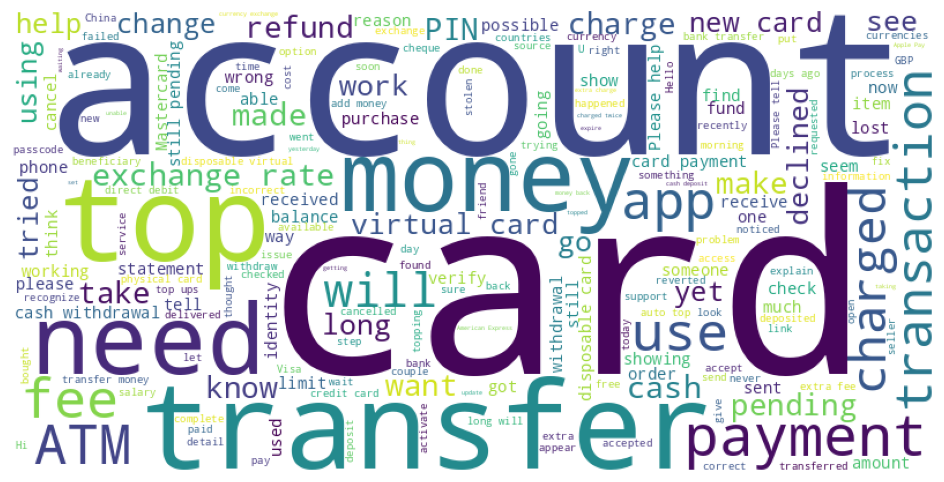

In [ ]:
todo_el_texto=' '.join(df['texto'].astype(str))

nube_palabras=WordCloud(width=800,height=400,background_color='white').generate(todo_el_texto)

plt.figure(figsize=(12,6))
plt.imshow(nube_palabras)
plt.axis('off')
plt.show()

## 2) Preprocesamiento

### Limpieza de texto

In [ ]:
palabras_vacias=set(stopwords.words('english'))

def clean_text(text):
    text=text.lower()
    text=''.join([c for c in text if c not in string.punctuation])
    tokens=text.split()
    tokens=[w for w in tokens if w not in palabras_vacias]
    return ' '.join(tokens)

df['texto_limpio']=df['texto'].apply(clean_text)

df[['texto','texto_limpio']].head()

,texto,texto_limpio
0,I am still waiting on my card?,still waiting card
1,What can I do if my card still hasn't arrived ...,card still hasnt arrived 2 weeks
2,I have been waiting over a week. Is the card s...,waiting week card still coming
3,Can I track my card while it is in the process...,track card process delivery
4,"How do I know if I will get my card, or if it ...",know get card lost


### Codificación de categorías

In [ ]:
codificador_etiquetas=LabelEncoder()
df['etiqueta']=codificador_etiquetas.fit_transform(df['categoria'])

print('Cantidad de clases:',len(codificador_etiquetas.classes_))
df[['categoria','etiqueta']].head()

Cantidad de clases: 77


,categoria,etiqueta
0,card_arrival,12
1,card_arrival,12
2,card_arrival,12
3,card_arrival,12
4,card_arrival,12


### Representación vectorial (BoW)

In [ ]:
vectorizador_conteo=CountVectorizer(max_features=5000)
X_cv=vectorizador_conteo.fit_transform(df['texto_limpio']).toarray()
y=df['etiqueta']

print(X_cv.shape)

(13083, 2511)


In [ ]:
vocabulario = pd.DataFrame(
    vectorizador_conteo.get_feature_names_out(),
    columns=['Termino']
)

### Representación TF-IDF


In [ ]:
vectorizador_tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = vectorizador_tfidf.fit_transform(df['texto_limpio']).toarray()

print(X_tfidf.shape)

(13083, 2511)


### Balance del conjunto

Distribución original:
etiqueta
0     202
1     199
2     150
3     166
4     127
     ... 
72     81
73    175
74    161
75    220
76    203
Name: count, Length: 77, dtype: int64

Distribución luego de SMOTE (BoW):
etiqueta
0     227
1     227
2     227
3     227
4     227
     ... 
72    227
73    227
74    227
75    227
76    227
Name: count, Length: 77, dtype: int64


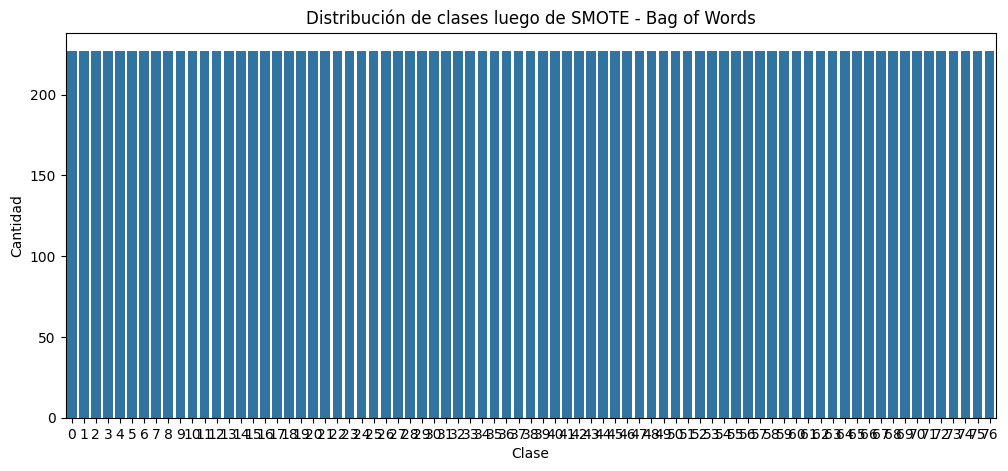

In [ ]:
smote_cv = SMOTE(random_state=42)

X_cv_res, y_cv_res = smote_cv.fit_resample(X_cv,y)

print("Distribución original:")
print(pd.Series(y).value_counts().sort_index())

print("\nDistribución luego de SMOTE (BoW):")
print(pd.Series(y_cv_res).value_counts().sort_index())

plt.figure(figsize=(12,5))
sns.countplot(x=y_cv_res)
plt.title("Distribución de clases luego de SMOTE - Bag of Words")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()


Distribución luego de SMOTE (TF-IDF):
etiqueta
0     227
1     227
2     227
3     227
4     227
     ... 
72    227
73    227
74    227
75    227
76    227
Name: count, Length: 77, dtype: int64


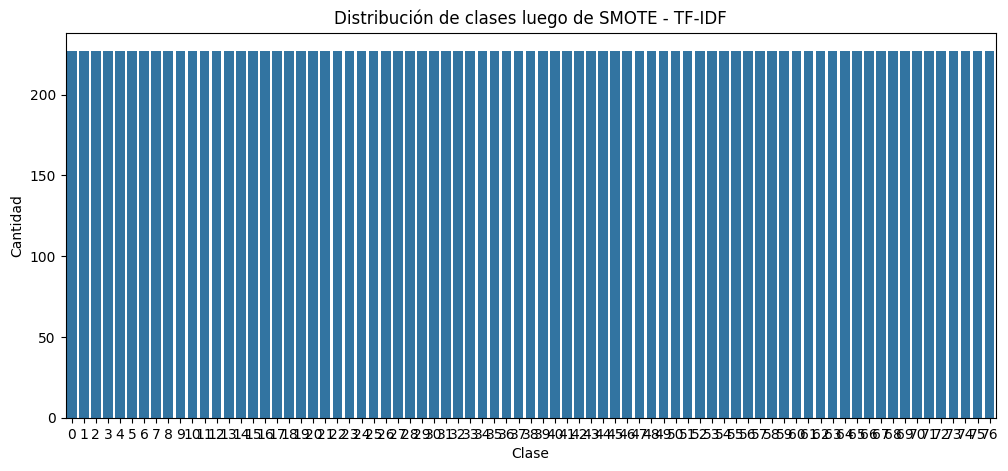

In [ ]:
smote_tfidf = SMOTE(random_state=42)

X_tfidf_res, y_tfidf_res = smote_tfidf.fit_resample(X_tfidf,y)

print("\nDistribución luego de SMOTE (TF-IDF):")
print(pd.Series(y_tfidf_res).value_counts().sort_index())


plt.figure(figsize=(12,5))
sns.countplot(x=y_tfidf_res)
plt.title("Distribución de clases luego de SMOTE - TF-IDF")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

In [ ]:
print("\nResumen de dimensiones:")
print(f"BoW original: {X_cv.shape}")
print(f"BoW balanceado: {X_cv_res.shape}")

print(f"\nTF-IDF original: {X_tfidf.shape}")
print(f"TF-IDF balanceado: {X_tfidf_res.shape}")


Resumen de dimensiones:
BoW original: (13083, 2511)
BoW balanceado: (17479, 2511)

TF-IDF original: (13083, 2511)
TF-IDF balanceado: (17479, 2511)


## 3) Entrenamiento de Modelos

### División entrenamiento/prueba

In [ ]:
X_cv_entrenamiento, X_cv_prueba, y_cv_entrenamiento, y_cv_prueba = train_test_split(X_cv_res, y_cv_res, test_size=0.2, random_state=42)
X_tfidf_entrenamiento, X_tfidf_prueba, y_tfidf_entrenamiento, y_tfidf_prueba = train_test_split(X_tfidf_res, y_tfidf_res, test_size=0.2, random_state=42)

### Modelo Base

In [ ]:
modelos={
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100,random_state=42),
    'Naive Bayes': MultinomialNB()
}

resultados_precision = []

def evaluar_modelos(X_entrenamiento, X_prueba, y_entrenamiento, y_prueba, nombre_vectorizador):
    print(f"\n Resultados con {nombre_vectorizador}:\n" + "-"*40)
    for nombre, modelo in modelos.items():
        modelo.fit(X_entrenamiento, y_entrenamiento)
        y_pred = modelo.predict(X_prueba)
        precision_modelo = accuracy_score(y_prueba, y_pred)
        print(f"\n Modelo: {nombre}")
        print("Accuracy:", precision_modelo)
        print(classification_report(y_prueba, y_pred, target_names=codificador_etiquetas.classes_))

         # Guardar en la lista global
        resultados_precision.append({
            'Modelo': nombre,
            'Vectorización': nombre_vectorizador,
            'Accuracy': precision_modelo
        })
    print(classification_report(y_prueba,y_pred))

### Evaluación antes del ajuste de hiperparámetros

In [ ]:
# Evaluación con BoW
evaluar_modelos(X_cv_entrenamiento, X_cv_prueba, y_cv_entrenamiento, y_cv_prueba, "Bag of Words")

# Evaluación con TF-IDF
evaluar_modelos(X_tfidf_entrenamiento, X_tfidf_prueba, y_tfidf_entrenamiento, y_tfidf_prueba, "TF-IDF")


 Resultados con Bag of Words:
----------------------------------------

 Modelo: Logistic Regression
Accuracy: 0.8601258581235698
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.92      0.88      0.90        50
                                activate_my_card       0.98      1.00      0.99        53
                                       age_limit       0.98      0.96      0.97        54
                         apple_pay_or_google_pay       0.98      0.98      0.98        51
                                     atm_support       0.92      0.94      0.93        49
                                automatic_top_up       0.97      0.90      0.94        41
         balance_not_updated_after_bank_transfer       0.67      0.69      0.68        35
balance_not_updated_after_cheque_or_cash_deposit       0.89      0.85      0.87        46
                         beneficiary_not_allowed       0.8

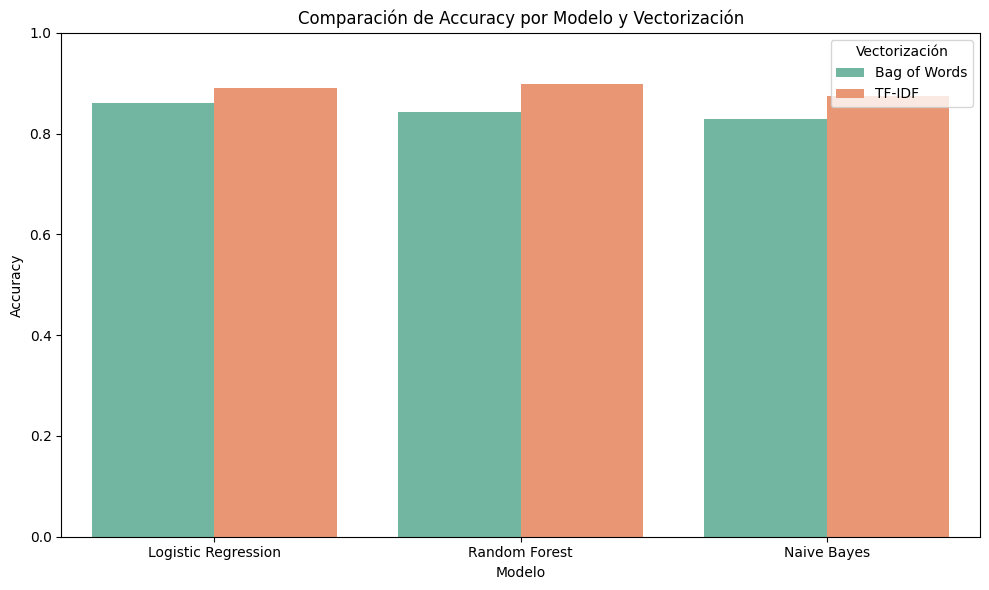

In [ ]:
df_resultados = pd.DataFrame(resultados_precision)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_resultados, x='Modelo', y='Accuracy', hue='Vectorización', palette='Set2')
plt.title('Comparación de Accuracy por Modelo y Vectorización')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Busqueda de hiperparámetros

#### Logistic Regression

In [ ]:
rejilla_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    {
        'C':[0.01,0.1,1,10],
        'solver':['liblinear']
    },
    cv=3,
    scoring='accuracy'
)

rejilla_lr.fit(X_tfidf_entrenamiento, y_tfidf_entrenamiento)

print("Mejores parámetros:")
print(rejilla_lr.best_params_)
print("Mejor score CV:")
print(rejilla_lr.best_score_)

Mejores parámetros:
{'C': 10, 'solver': 'liblinear'}
Mejor score CV:
0.8971608381606235


### Random Forest

In [ ]:
rejilla_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        'n_estimators':[100,200],
        'max_depth':[10,20,None],
        'min_samples_split':[2,5]
    },
    cv=3,
    scoring='accuracy'
)

rejilla_rf.fit(X_tfidf_entrenamiento, y_tfidf_entrenamiento)

print("Mejores parámetros:")
print(rejilla_rf.best_params_)
print("Mejor score CV:")
print(rejilla_rf.best_score_)

Mejores parámetros:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Mejor score CV:
0.8812844167918187


### Naive Bayes

In [ ]:
rejilla_nb = GridSearchCV(
    MultinomialNB(),
    {
        'alpha':[0.01,0.1,1,10]
    },
    cv=3,
    scoring='accuracy'
)

rejilla_nb.fit(X_tfidf_entrenamiento, y_tfidf_entrenamiento)

print("Mejores parámetros:")
print(rejilla_nb.best_params_)
print("Mejor score CV:")
print(rejilla_nb.best_score_)

Mejores parámetros:
{'alpha': 0.1}
Mejor score CV:
0.881785024672817


In [ ]:
mejores_modelos = {
    'Logistic Regression': rejilla_lr.best_estimator_,
    'Random Forest': rejilla_rf.best_estimator_,
    'Naive Bayes': rejilla_nb.best_estimator_
}

for nombre, modelo in mejores_modelos.items():

    predicciones = modelo.predict(X_tfidf_prueba)

    print("\n", "="*50)
    print(nombre)
    print("="*50)

    print("Accuracy:",
          accuracy_score(y_tfidf_prueba, predicciones))

    print(classification_report(
        y_tfidf_prueba,
        predicciones,
        target_names=codificador_etiquetas.classes_
    ))


Logistic Regression
Accuracy: 0.9056064073226545
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.94      0.96      0.95        50
                                activate_my_card       1.00      1.00      1.00        53
                                       age_limit       0.96      0.98      0.97        54
                         apple_pay_or_google_pay       1.00      0.98      0.99        51
                                     atm_support       0.94      0.94      0.94        49
                                automatic_top_up       0.97      0.93      0.95        41
         balance_not_updated_after_bank_transfer       0.74      0.71      0.72        35
balance_not_updated_after_cheque_or_cash_deposit       0.91      0.89      0.90        46
                         beneficiary_not_allowed       0.93      0.84      0.88        49
                                 cancel_transfer 

### Comparaciones

In [ ]:
resultados_finales = []

for nombre, modelo in mejores_modelos.items():

    predicciones = modelo.predict(X_tfidf_prueba)

    resultados_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_tfidf_prueba, predicciones)
    })

pd.DataFrame(resultados_finales).sort_values(
    "Accuracy",
    ascending=False
)

,Modelo,Accuracy
0,Logistic Regression,0.905606
1,Random Forest,0.899314
2,Naive Bayes,0.894451
